# FINC 430 Project Portfolio — Step 2: Exploratory Data Analysis
### Dataset: JKP U.S. factor themes (monthly returns, 13 investing strategies)

**Goal of this step:** before we build any model (Step 3 is KNN), get to know the data. We check what is in it, how each strategy performed, how bumpy each one is, and whether the strategies move together.

**How to run (Colab, R runtime):** upload `[usa]_[all_themes]_[monthly]_[vw_cap].csv` to the Files pane on the left, then run each cell from top to bottom. If you uploaded the **.zip** instead, run `system("unzip -o *.zip")` in a cell first.

**Every code line ends with a `#` comment** that explains it in plain words. After each code cell there is a short breakdown of what the whole cell does.

## 1. Load the packages and the data

In [1]:
for (p in c("data.table", "ggplot2")) if (!requireNamespace(p, quietly = TRUE)) install.packages(p)   # install the packages only if Colab is missing them
library(data.table)                                         # load data.table (fast reading and grouping of data)
library(ggplot2)                                            # load ggplot2 (makes the charts)
zip_name <- list.files(pattern = "zip$")[1]                 # look for an uploaded zip file (NA if there is none)
if (!is.na(zip_name)) unzip(zip_name)                       # if a zip was uploaded, unzip it into the current folder
csv_name <- list.files(pattern = "all_themes.*csv$")[1]     # find the CSV by part of its file name
if (is.na(csv_name)) stop("No data file found. Upload the zip or csv to the Files pane and run this cell again.")   # clear message if nothing was uploaded
raw <- fread(csv_name)                                      # read the CSV into a table called raw
raw[, date := as.Date(date)]                                # turn the date column into real dates


Attaching package: ‘data.table’


The following object is masked from ‘package:base’:

    %notin%




**What this cell does:** it loads the two tools we use (`data.table` for the data, `ggplot2` for charts), finds the CSV you uploaded, reads it into a table called `raw`, and converts the `date` column into real dates so R can sort and filter by time.

**Link to the assignment:** this is the starting point of the EDA, getting the dataset into R.

## 2. First look at the data

In [2]:
dim(raw)                                                    # number of rows and columns in the file
head(raw)                                                   # first 6 rows: each row is one theme in one month
raw[, uniqueN(name)]                                        # how many different themes there are (13)
sum(is.na(raw$ret))                                         # count of missing returns (0 means none missing)
raw[, .(first_month = min(date)), by = name]                # first month of data for each theme
raw <- raw[date >= "1952-01-01"]                            # keep January 1952 onward (all 13 themes exist by then)
nrow(raw)                                                   # rows left in our analysis sample

[1] 14945     7

location,name,freq,weighting,n_factors,date,ret
<chr>,<chr>,<chr>,<chr>,<int>,<date>,<dbl>
usa,accruals,monthly,vw_cap,1,1946-01-31,0.019329176
usa,accruals,monthly,vw_cap,1,1946-02-28,-0.014672145
usa,accruals,monthly,vw_cap,1,1946-03-31,0.041285190
usa,accruals,monthly,vw_cap,1,1946-04-30,0.008244289
usa,accruals,monthly,vw_cap,1,1946-05-31,0.021620176
usa,accruals,monthly,vw_cap,1,1946-06-30,-0.010599821


[1] 13

[1] 0

name,first_month
<chr>,<date>
accruals,1946-01-31
debt_issuance,1951-11-30
investment,1931-01-31
low_leverage,1926-02-28
low_risk,1926-02-28
momentum,1926-04-30
profit_growth,1927-01-31
profitability,1926-04-30
quality,1927-01-31


[1] 11544

**What this cell does:** it checks the basics: how big the file is, what a row looks like, how many themes there are, and whether any returns are missing. Then it shows when each theme starts and cuts the data to start in **January 1952**.

**Why 1952:** the themes start at different times. The last one (`debt_issuance`) only begins in November 1951. In the early years each theme is built from only a few ingredient factors, so the returns are extreme and noisy. Starting in 1952 gives us all 13 themes on the same dates, with cleaner data.

**Reading the file:** one row is one theme in one month. `ret` is the return (0.01 means 1%). Our sample is 13 themes × 888 months = 11,544 rows.

## 3. How did each theme perform?

In [3]:
stats <- raw[, .(avg_pct   = round(1200 * mean(ret), 2),             # average return per year, in % (monthly average x 12 x 100)
                 vol_pct   = round(100 * sqrt(12) * sd(ret), 2),     # yearly volatility, in % (how bumpy the ride is)
                 sharpe    = round(sqrt(12) * mean(ret) / sd(ret), 2), # return per unit of bumpiness (bigger is better)
                 worst_pct = round(100 * min(ret), 1),               # worst single month, in %
                 pct_up    = round(100 * mean(ret > 0), 1)),         # share of months with a positive return, in %
             by = name]                                              # do all of the above separately for each theme
stats[order(-sharpe)]                                                # show the table, best Sharpe first

name,avg_pct,vol_pct,sharpe,worst_pct,pct_up
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
debt_issuance,2.43,2.39,1.02,-2.6,62.7
seasonality,1.64,1.83,0.89,-2.3,61.8
accruals,2.80,3.82,0.73,-3.8,58.2
quality,3.40,5.14,0.66,-6.7,61.0
profit_growth,2.29,3.58,0.64,-6.8,62.3
short_term_reversal,2.02,4.01,0.50,-8.3,56.1
momentum,4.77,10.36,0.46,-22.2,60.9
investment,2.83,6.81,0.42,-10.3,53.4
profitability,2.59,6.64,0.39,-14.2,56.4


**What this cell does:** it builds one summary table with a row per theme. For each theme it computes the average yearly return, how bumpy it is (volatility), the Sharpe ratio (return divided by bumpiness, so bigger means a better reward for the risk), the worst month, and how often the theme went up.

**How to read it:** a theme with a high average but huge volatility is less attractive than one with a modest average and low volatility. The Sharpe column puts them on the same footing.

## 4. Chart 1: growth of each theme over time

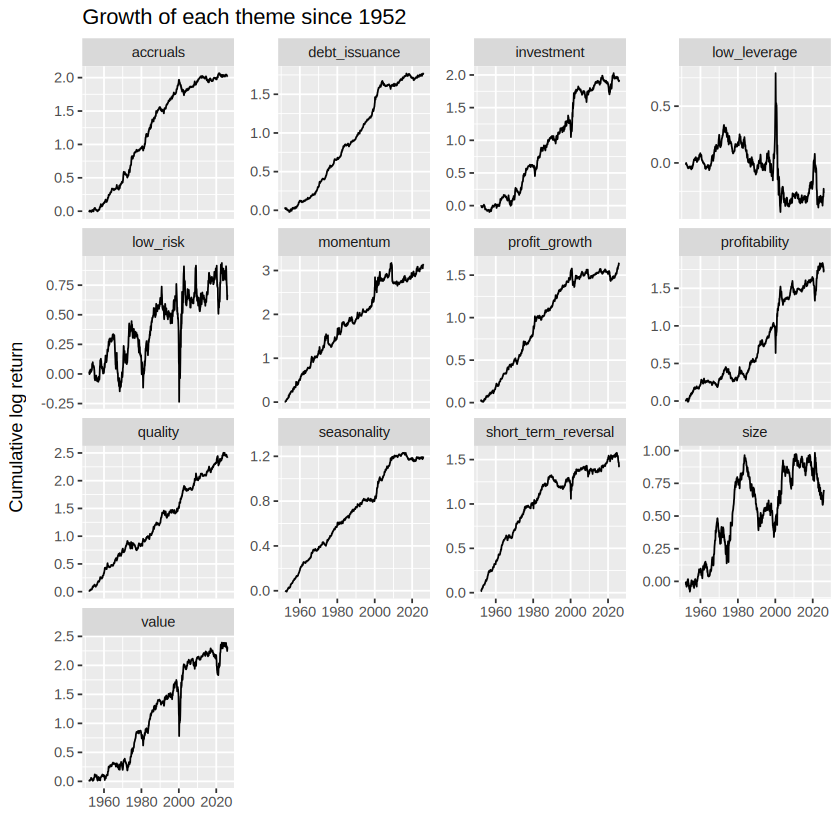

In [4]:
raw <- raw[order(name, date)]                               # sort by theme, then date, so running totals are in order
raw[, cum := cumsum(log1p(ret)), by = name]                 # running total of each theme's returns (a growth line)
ggplot(raw, aes(date, cum)) +                               # start the chart: date on the x-axis, running total on the y-axis
  geom_line() +                                             # draw each theme as a line
  facet_wrap(~ name, scales = "free_y") +                   # one small chart per theme, each with its own y-axis
  labs(title = "Growth of each theme since 1952", x = "", y = "Cumulative log return")   # title and axis labels

**What this cell does:** it adds up each theme's monthly returns over time and draws one small chart per theme. A line that rises steadily means the theme kept earning. A flat line means the theme stopped paying. A sharp drop is a crash.

**How to read it:** look at the *shape*, not the height, because each chart has its own y-axis. Many themes rise steadily for decades and then flatten out after about 2000. The value chart shows a sharp drop in 2000.

## 5. Chart 2: how bumpy is each theme month to month?

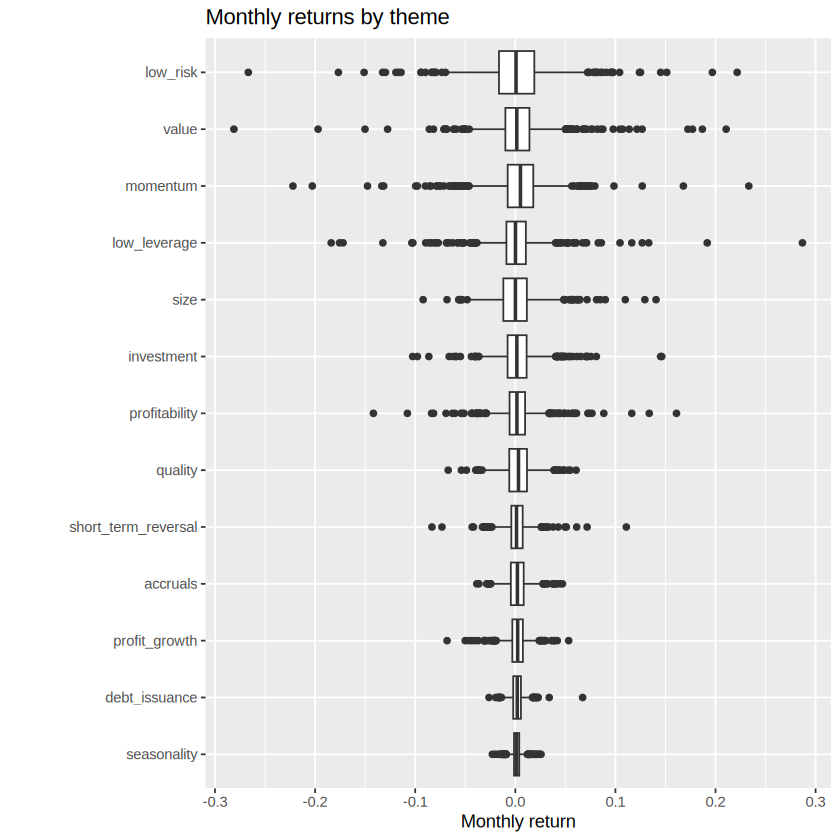

In [5]:
ggplot(raw, aes(reorder(name, ret, sd), ret)) +             # one box per theme, ordered by bumpiness (bumpiest on top)
  geom_boxplot() +                                          # draw the boxes (dots are unusually big or small months)
  coord_flip() +                                            # flip sideways so the theme names are easy to read
  labs(title = "Monthly returns by theme", x = "", y = "Monthly return")   # title and axis labels

**What this cell does:** it draws a box for each theme showing its typical monthly return. The box covers the middle half of all months, the line inside it is the median, and the dots are unusually big gains or losses.

**How to read it:** wider boxes mean a bumpier theme. Lots of dots far from the box means the theme has some extreme months. That matters for prediction in Step 3, because a few giant months can dominate the results.

## 6. Chart 3: do the themes move together?

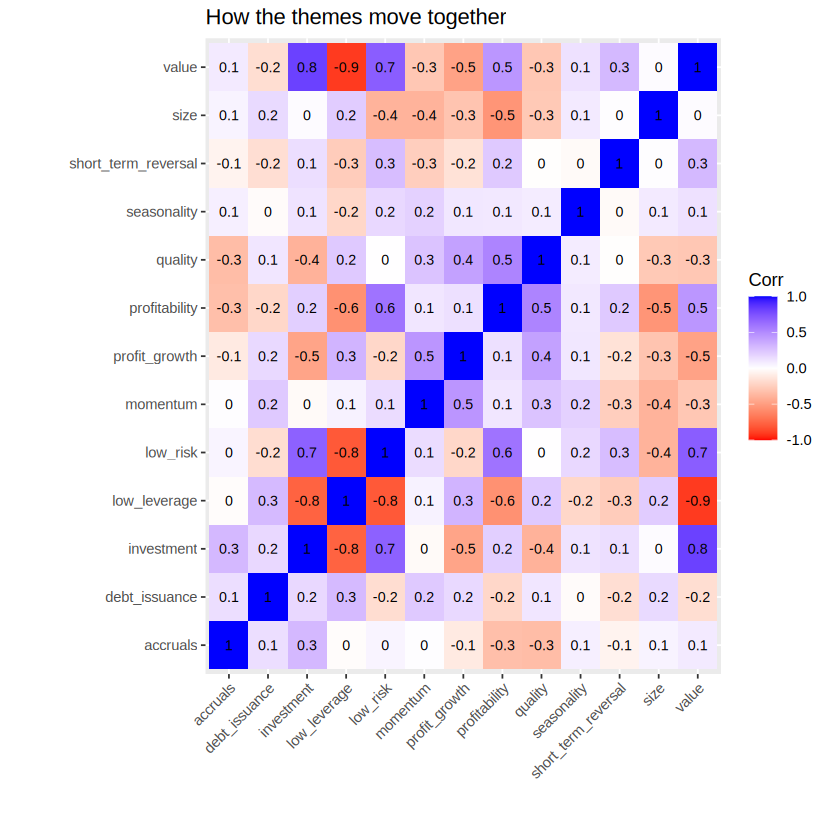

In [6]:
wide <- dcast(raw, date ~ name, value.var = "ret")          # reshape: one column per theme, one row per month
cm <- cor(wide[, !"date"])                                  # correlation of every theme with every other theme (13 x 13)
cm_long <- as.data.table(as.table(cm))                      # turn the matrix into a long table so ggplot can draw it
ggplot(cm_long, aes(V1, V2, fill = N)) +                    # heatmap: theme vs theme, colored by the correlation N
  geom_tile() +                                             # draw a colored square for each pair
  geom_text(aes(label = round(N, 1)), size = 3) +           # write the correlation number inside each square
  scale_fill_gradient2(low = "red", mid = "white", high = "blue", limits = c(-1, 1)) +   # red = opposite, blue = together
  theme(axis.text.x = element_text(angle = 45, hjust = 1)) +   # tilt the x-axis labels so they fit
  labs(title = "How the themes move together", x = "", y = "", fill = "Corr")   # title and labels

**What this cell does:** it measures, for every pair of themes, whether they tend to have good and bad months at the same time. The number runs from −1 to +1. **+1** means they move in lockstep, **0** means no link, and **−1** means mirror images. The heatmap colors each pair: blue means they move together, red means they move opposite.

**How to read it:** if all 13 themes moved together, they would really be one bet. Strong blue or red squares show which themes are partly the same bet in disguise.

## 7. Takeaways
*(These are drafts. Edit them in your own words.)*

1. **The data is clean and sized right.** 13 themes × 888 months (January 1952 to December 2025) = 11,544 rows, with no missing returns. We start in 1952 because that is when all 13 themes exist and the early data is thin and noisy.
2. **Rewards are modest.** Average returns run from about 0% to 4.8% a year. The biggest are momentum (4.8%) and value (3.7%). `low_leverage` earns almost nothing (0.08% a year, Sharpe about 0.01).
3. **The steadiest themes are the quiet ones.** `debt_issuance` (Sharpe 1.02), `seasonality` (0.89), and `accruals` (0.73) give the best reward per unit of bumpiness. Famous themes like value (0.35) and momentum (0.46) are less steady.
4. **Some themes are very bumpy.** `low_risk`, `value`, and `momentum` swing about 10 to 12% a year, and value had a −28.1% month. Extreme months (the dots in the boxplot) are common, and they show up as sharp drops in the growth charts, such as value in 2000. Many themes also flatten out after about 2000.
5. **The themes are partly the same bet.** Value and `low_leverage` move in opposite directions (about −0.9), and value moves with `investment` (+0.8) and `low_risk` (+0.7). Most other pairs are close to zero.
6. **What this means for Step 3.** Monthly swings are large compared with the average return, and a few extreme months can dominate. So we should expect predicting next month's return to be hard, and we should judge any model against a simple benchmark.